# Chapter 1 · Exploratory Data Analysis

Explore the data through summaries and visualizations
to understand its characteristics and discover patterns.

## Introduction · Why Explore the Data?

**Exploratory Data Analysis (EDA):**
Examining data using numerical summaries and visualizations.

**Statistical inference:**
Drawing conclusions about a population using sample data.

EDA helps us understand the observations and identify questions
worth investigating.

# Part 1 · Understanding the Data

Identify what each observation represents,
what each variable means, and how the data is organized.

### John Tukey’s Contribution

- **1962 — The Future of Data Analysis**
  Proposed a broader discipline of data analysis,
  with statistical inference as one component.

- **1977 — Exploratory Data Analysis**
  Established an influential approach combining
  simple plots with numerical summaries.

**Summaries and visualizations work together to reveal the data.**

### From EDA to Data Science

Data analysis expanded with:

- Greater computing power and better software.
- Access to larger and more varied datasets.
- Wider use of quantitative methods.

**The foundation remains: look at and understand the data.**

## 1.1 · Elements of Structured Data

Data comes from many sources:
sensors, events, text, images, videos, and clickstreams.

**Structured data:** Data organized into defined fields,
commonly as a table of rows and columns.

Raw data often needs processing into structured features
before applying the statistical methods in this book.

### Key Terms · Numeric Data

**Numeric:** Values representing quantities on a numeric scale.

| Type | Definition | Example |
|---|---|---|
| Continuous | Values that can vary over an interval | Wind speed, duration |
| Discrete | Distinct possible values, such as counts | Number of clicks |

**Measurement precision does not determine the type.**
Rounding a duration to whole seconds does not make time discrete.

### Key Terms · Categorical Data

**Categorical:** Values representing a defined set of categories.
Also called nominal data when categories have no inherent order.

| Type | Definition | Example |
|---|---|---|
| Nominal | Categories without an inherent order | Mobile, desktop, tablet |
| Binary | Exactly two possible categories | Yes/no, true/false |
| Ordinal | Categories with a meaningful order | Low < Medium < High |

**Ordered categories do not necessarily have equal gaps.**
A rating of 4 is not necessarily twice as much satisfaction as 2.

### Example · Identify the Variable Types

Each row below represents one app session.

Identify the measurements, counts, and categories.

*Synthetic data for illustration.*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from scipy.stats import (
    trim_mean,
    median_abs_deviation,
    gaussian_kde,
)

sns.set_theme(style="whitegrid", context="talk")

In [2]:
import pandas as pd

sessions = pd.DataFrame({
    "Duration_seconds": [42.5, 180.2, 75.0, 240.8],
    "Clicks": [3, 12, 5, 18],
    "Device": ["Mobile", "Desktop", "Mobile", "Tablet"],
    "Purchased": [False, True, False, True],
    "Satisfaction": ["Medium", "High", "Low", "High"],
})

sessions

,Duration_seconds,Clicks,Device,Purchased,Satisfaction
0,42.5,3,Mobile,False,Medium
1,180.2,12,Desktop,True,High
2,75.0,5,Mobile,False,Low
3,240.8,18,Tablet,True,High


### Why Explicit Data Types Matter

Data types guide:

- **Analysis:** Which summaries, charts, and models are appropriate.
- **Software behavior:** How values are ordered and processed.
- **Storage:** How values can be represented efficiently.
- **Validation:** Which categories are allowed.

**Statistical meaning and software storage are different.**
Numbers can represent categories; text can represent an ordered scale.

In [3]:
sessions["Device"] = sessions["Device"].astype("category")

sessions["Satisfaction"] = pd.Categorical(
    sessions["Satisfaction"],
    categories=["Low", "Medium", "High"],
    ordered=True,
)

sessions[["Satisfaction", "Device"]].sort_values("Satisfaction")

,Satisfaction,Device
2,Low,Mobile
0,Medium,Mobile
1,High,Desktop
3,High,Tablet


### Key Takeaways

- Numeric data includes continuous measurements and discrete counts.
- Categorical data includes binary and ordinal variables.
- Explicit ordering preserves meaning: Low → Medium → High.
- A fixed category list needs updating when legitimate new values appear.

**Choose the data type from what the variable means.**

## 1.2 · Rectangular Data

**Rectangular data:** A two-dimensional structure in which
rows represent records and columns represent variables.

**Data frame:** A table-like structure used in Python to hold
rectangular data. Columns can have different data types.

Before analyzing: **What does one row represent?**

### Key Terms

| Term | Meaning | Common synonyms |
|---|---|---|
| Record | One row of observations | Case, instance, example |
| Feature | A variable used as an input | Attribute, predictor |
| Outcome | The variable we want to predict | Response, target, dependent variable |

**Terminology trap:**
“Sample” may mean one row in machine learning,
but a collection of observations in statistics.

### Example · Sessions as Rectangular Data

- **Record:** One app session.
- **Variables:** Duration, clicks, device, purchase, satisfaction.
- **Possible outcome:** Whether a purchase occurred.

A variable’s role depends on the question.
**Exploration does not require a prediction target.**

In [4]:
print(f"Records: {sessions.shape[0]}")
print(f"Variables: {sessions.shape[1]}")

sessions

Records: 4
Variables: 5


,Duration_seconds,Clicks,Device,Purchased,Satisfaction
0,42.5,3,Mobile,False,Medium
1,180.2,12,Desktop,True,High
2,75.0,5,Mobile,False,Low
3,240.8,18,Tablet,True,High


### Data Frames and Indexes

**Index:** Labels used to identify, select, and align rows in pandas.

- Default: integers starting at 0.
- Custom: meaningful labels, such as session IDs.
- Hierarchical: multiple levels, such as user and session.

**An index is not automatically a feature or a unique identifier.**

In [5]:
sessions.index = pd.Index(
    ["S01", "S02", "S03", "S04"],
    name="Session_ID",
)

# Select a record by its label.
sessions.loc[["S03"]]

,Duration_seconds,Clicks,Device,Purchased,Satisfaction
Session_ID,,,,,
S03,75.0,5,Mobile,False,Low


### Beyond Rectangular Data

| Structure | What matters | Example |
|---|---|---|
| Time series | Time order and dependence | Sensor readings |
| Spatial · Objects | Entities and their locations | Houses with coordinates |
| Spatial · Fields | Values across an area | Temperature grid |
| Graph / Network | Entities and their connections | Social network |

These can sometimes be stored in tables,
but their additional structure still matters.

### “Graph” Has Two Meanings

- **Statistics:** A plot or visual display.
- **Computing:** A structure of nodes and connections.

### Key Takeaways

- Define what each row represents.
- Identify the meaning and role of each column.
- Preserve relevant time, spatial, or network relationships.

**Next: Estimates of Location — what is a useful “typical” value?**

# Part 2 · Estimates of Location

## 2.1 · What Is a Typical Value?

**Estimate of location:** A value describing the center
or typical level of a variable.

Also called a measure of **central tendency**.

Different measures answer this question differently:
the mean is useful, but it is not always the best choice.

### Terminology · Estimate and Metric

**Estimate:** A value calculated from observed data,
often used to approximate an unknown population quantity.

**Metric:** A numerical measure used to describe or track something.

The term “estimate” emphasizes uncertainty.

## 2.2 · Mean

**Mean (average):** The sum of the values divided by their count.

$$
\bar{x} = \frac{\sum_{i=1}^{n} x_i}{n}
$$

- $x_i$: an individual observation.
- $n$: number of observations.
- $\bar{x}$: sample mean, pronounced “x-bar.”

In [6]:
import numpy as np
# Remember the dof in  numby !!!!!
# Example from the book
values = np.array([3, 5, 1, 2])

print(f"Sum: {values.sum()}")
print(f"Count: {values.size}")
print(f"Mean: {values.mean():.2f}")

Sum: 11
Count: 4
Mean: 2.75


## 2.3 · Trimmed Mean

**Trimmed mean:** The mean after removing the same number
of observations from each end of the sorted data.

1. Sort the values.
2. Remove the lowest and highest values.
3. Average the remaining values.

**Purpose:** Reduce the influence of extreme observations.

### Trimmed Mean · Formula

After removing $p$ observations from each end:

$$
\bar{x}_{\mathrm{trim}}
=
\frac{\sum_{i=p+1}^{n-p} x_{(i)}}{n-2p}
$$

$x_{(i)}$ denotes the value in position $i$ after sorting.

**Example:** With five values and $p=1$, average the middle three.

In [7]:
# Synthetic scores: remove one value from each end
scores = np.array([2.0, 8.0, 8.5, 9.0, 9.5])

sorted_scores = np.sort(scores)
retained_scores = sorted_scores[1:-1]

print("Sorted scores:", sorted_scores)
print("Retained scores:", retained_scores)
print(f"Mean: {scores.mean():.2f}")
print(f"Trimmed mean: {retained_scores.mean():.2f}")

Sorted scores: [2.  8.  8.5 9.  9.5]
Retained scores: [8.  8.5 9. ]
Mean: 7.40
Trimmed mean: 8.50


### Interpretation

- **Mean: 7.40** — uses all five scores.
- **Trimmed mean: 8.50** — uses the middle three.

Trimming reduces the influence of the extreme scores.

**An extreme value is not automatically an error.**
Trimming changes the summary; it does not prove a value is invalid.

## 2.4 · Weighted Mean

**Weighted mean:** An average in which each value
contributes according to its assigned weight.

$$
\bar{x}_w = \frac{\sum_{i=1}^{n} w_i x_i}{\sum_{i=1}^{n} w_i}
$$

- $x_i$: an observed value.
- $w_i$: its weight.

With equal weights, this becomes the ordinary mean.

### Why Use Weights?

- **Different precision:** Give less weight to noisier measurements.
- **Unequal representation:** Adjust contributions when groups
  are underrepresented or overrepresented.

**Weights must reflect the question and have a justified basis.**

### Example · Unequal Group Sizes

Two groups completed the same assessment:

| Group | Mean score | Number of participants |
|---|---:|---:|
| A | 80 | 10 |
| B | 60 | 30 |

**Question:** What is the mean score across all 40 participants?

*Synthetic example. Group sizes are the weights.*

In [8]:
import numpy as np

group_means = np.array([80, 60])
group_sizes = np.array([10, 30])

print(f"Unweighted mean: {group_means.mean():.1f}")
print(
    f"Participant-weighted mean: "
    f"{np.average(group_means, weights=group_sizes):.1f}"
)

Unweighted mean: 70.0
Participant-weighted mean: 65.0


### Interpretation

$$
\bar{x}_w = \frac{80(10) + 60(30)}{10 + 30} = 65
$$

- **70:** Gives each group equal weight.
- **65:** Gives each participant equal weight.

Group B contributes more because it contains more participants.

**The choice of weights determines what the average represents.**

## 2.5 · Median and Robust Estimates

**Median:** The middle value of the sorted data.
Also called the **50th percentile**.

- **Odd number of values:** Take the middle value.
- **Even number of values:** Average the two middle values.

The median depends on the center of the sorted data,
rather than the magnitude of every observation.

In [9]:
import numpy as np

odd_values = np.array([1, 3, 5, 7, 9])
even_values = np.array([1, 3, 5, 7])

print(f"Odd count — median: {np.median(odd_values):.1f}")
print(f"Even count — median: {np.median(even_values):.1f}")

Odd count — median: 5.0
Even count — median: 4.0


### Key Terms · Robustness and Outliers

**Robust (resistant):** Relatively insensitive to extreme values.

**Outlier:** An observation very different from most other observations.

The median is a robust estimate of location.
The mean is sensitive to extreme values.

### Example · One Extremely High Income

We replace the highest income with a much larger value.

**Question:** How much will the mean and median change?

*Synthetic annual incomes, expressed in thousands.*

In [10]:
import pandas as pd

incomes = np.array([40, 45, 50, 55, 60])
with_extreme = np.array([40, 45, 50, 55, 1000])

pd.DataFrame({
    "Dataset": ["Original", "With extreme income"],
    "Mean": [incomes.mean(), with_extreme.mean()],
    "Median": [np.median(incomes), np.median(with_extreme)],
}).set_index("Dataset")

,Mean,Median
Dataset,,
Original,50.0,50.0
With extreme income,238.0,50.0


### Interpretation

- The mean rises from **50 to 238**.
- The median stays at **50**.

The extreme income changes the total,
but leaves the middle observation unchanged.

**Robust does not mean immune to every change in the data.**

### Outliers Deserve Investigation

An extreme observation may be:

- A genuine, unusual case.
- A measurement or recording error.
- A unit mismatch, such as meters versus kilometers.

**Being unusual does not make a value invalid.**

In anomaly detection, unusual observations may be
the main objects of interest.

### Choosing a Measure of Location

| Measure | Main characteristic |
|---|---|
| Mean | Uses every value; sensitive to extremes |
| Median | Uses the middle position; resistant to extremes |
| Trimmed mean | Removes both tails before averaging |

A trimmed mean balances using more observations
with reducing the influence of extreme values.

**Choose according to the question and the data.**

## 2.6 · Weighted Median

**Weighted median:** A value with no more than half
the total weight strictly below it or strictly above it.

Find the middle of the **weight**, rather than the middle
of the number of observations.

Useful when observations represent different numbers
of people or have different assigned importance.

### How to Find It

1. Sort the values, keeping their weights attached.
2. Calculate the cumulative weights.
3. Locate the point where cumulative weight reaches 50%.

If it reaches exactly 50% between two values,
any point in that interval satisfies the definition.
A common convention uses their midpoint.

### Example · Values Representing Different Numbers of People

| Value | Weight |
|---|---:|
| 10 | 1 |
| 20 | 6|
| 30 | 1 |
| 40 | 1 |
| 50 | 1 |

**Total weight: 10 · Half the weight: 5**

*Synthetic example.*

In [11]:
import numpy as np
import pandas as pd

values = np.array([10, 20, 30, 40, 50])
weights = np.array([1, 6, 1, 1, 1])

order = np.argsort(values)
values = values[order]
weights = weights[order]

cumulative_weight = np.cumsum(weights)

display(pd.DataFrame({
    "Value": values,
    "Weight": weights,
    "Cumulative weight": cumulative_weight,
    "Cumulative share": cumulative_weight / weights.sum(),
}))

half_weight = weights.sum() / 2
position = np.searchsorted(cumulative_weight, half_weight)

weighted_median = float(values[position])

# Use the midpoint when exactly half the weight is reached.
if cumulative_weight[position] == half_weight:
    weighted_median = (
                              float(values[position]) + float(values[position + 1])
                      ) / 2

print(f"Weighted median: {weighted_median:.1f}")

,Value,Weight,Cumulative weight,Cumulative share
0,10,1,1,0.1
1,20,6,7,0.7
2,30,1,8,0.8
3,40,1,9,0.9
4,50,1,10,1.0


Weighted median: 20.0


### Interpretation

The cumulative weight rises from **1 to 7** at value **20**,
crossing the halfway point of **5**.

- Ordinary median: **30**
- Weighted median: **20**

Weight strictly below 20: **1**
Weight strictly above 20: **3**

**Weighting changes where the middle lies.**

### Robustness Depends on the Weights

A weighted median resists extreme values
when those values carry little weight.

**An observation carrying more than half the total weight
determines the weighted median.**

Always inspect both the values and their weights.

## 2.7 · Example: State Populations and Murder Rates

**One row = one US state**

| Variable | Meaning |
|---|---|
| Population | State population |
| Murder.Rate | Annual murders per 100,000 people |

Historical data used in the book, with 2010 Census populations.

**Questions:**
- What is a typical state's population?
- How does population weighting change the average murder rate?

In [12]:
import numpy as np
import pandas as pd
from scipy.stats import trim_mean

url = (
    "https://raw.githubusercontent.com/gedeck/"
    "practical-statistics-for-data-scientists/master/data/state.csv"
)

state = pd.read_csv(url)
state.head()

,State,Population,Murder.Rate,Abbreviation
0,Alabama,4779736,5.7,AL
1,Alaska,710231,5.6,AK
2,Arizona,6392017,4.7,AZ
3,Arkansas,2915918,5.6,AR
4,California,37253956,4.4,CA


### Population · Compare Location Estimates

Calculate:

- Mean
- 10% trimmed mean
- Median

**10% trimming removes five states from each end
of the sorted populations: 10 states in total.**

In [13]:
population = state["Population"]

pd.Series({
    "Mean": population.mean(),
    "10% trimmed mean": trim_mean(population, proportiontocut=0.1),
    "Median": population.median(),
}, name="Population").round().astype(int)

Mean                6162876
10% trimmed mean    4783697
Median              4436370
Name: Population, dtype: int64

### Interpretation

| Measure | Population, approximately |
|---|---:|
| Mean | 6,162,876 |
| 10% trimmed mean | 4,783,697 |
| Median | 4,436,370 |

**Mean > Trimmed mean > Median**

Very large states pull the mean upward.
The three measures describe the center differently.

### Murder Rates · What Should Receive Equal Weight?

**Unweighted mean:** Each state contributes equally.

**Population-weighted mean:** Each state contributes
in proportion to its population.

For an overall rate across these populations,
use population weights.

The result is approximate because the supplied rates are rounded.

In [14]:
rates = state["Murder.Rate"]
weights = state["Population"]

pd.Series({
    "Unweighted mean rate": rates.mean(),
    "Population-weighted mean rate": np.average(
        rates, weights=weights
    ),
}, name="Murders per 100,000 people").round(3)

Unweighted mean rate             4.066
Population-weighted mean rate    4.446
Name: Murders per 100,000 people, dtype: float64

### Weighted Median · State Murder Rates

Sort the state rates and accumulate their populations.

The weighted median locates the halfway point
of the total population weight.

In [15]:
ordered = state.sort_values("Murder.Rate")
cumulative_population = ordered["Population"].cumsum()
half_population = ordered["Population"].sum() / 2

position = np.searchsorted(
    cumulative_population.to_numpy(),
    half_population,
)

weighted_median_rate = ordered["Murder.Rate"].iloc[position]

print(f"Population-weighted median rate: {weighted_median_rate:.1f}")

Population-weighted median rate: 4.4


### Interpretation and Takeaways

- Population-weighted mean rate: approximately **4.446**
- Population-weighted median state rate: **4.4**

The weighted median summarizes the distribution of
**state rates**, using population weights.

**Location measures answer different questions.**
Choose the measure—and the weights—to match your question.

# Part 3 · Estimates of Variability

## 3.1 · How Spread Out Are the Values?

**Variability (dispersion):** How tightly clustered
or spread out the observations are.

Two datasets can have the same center
but very different variability.

**Location alone does not describe the data.**

In [16]:
import numpy as np
import pandas as pd

groups = pd.DataFrame({
    "A": [9, 10, 11],
    "B": [0, 10, 20],
})

display(groups)
display(groups.mean().rename("Mean").to_frame())

,A,B
0,9,0
1,10,10
2,11,20


,Mean
A,10.0
B,10.0


### Interpretation

Both groups have a mean of **10**.

- **Group A:** Values stay close to the mean.
- **Group B:** Values are much farther apart.

A measure of variability captures this difference.

## 3.2 · Deviations

**Deviation:** The difference between an observation
and a chosen estimate of location.

For deviations from the mean:

$$
d_i = x_i - \bar{x}
$$

- Negative: below the mean.
- Positive: above the mean.
- Zero: equal to the mean.

In [17]:
# Example from the book
values = np.array([1, 4, 4])
deviations = values - values.mean()

display(pd.DataFrame({
    "Value": values,
    "Deviation from mean": deviations,
}))

print(f"Mean: {values.mean():.1f}")
print(f"Sum of deviations: {deviations.sum():.1f}")

,Value,Deviation from mean
0,1,-2.0
1,4,1.0
2,4,1.0


Mean: 3.0
Sum of deviations: 0.0


### Why Not Average the Deviations?

For [1, 4, 4], the mean is 3:

$$
(-2) + 1 + 1 = 0
$$

Deviations from the mean always sum to zero.

**Positive and negative differences cancel,
even when the observations are spread out.**

## 3.3 · Mean Absolute Deviation

**Mean absolute deviation:** The average absolute distance
of the observations from their mean.

$$
\frac{1}{n}\sum_{i=1}^{n}|x_i-\bar{x}|
$$

Absolute values prevent positive and negative deviations
from canceling.

**Units:** The same as the original variable.

In [18]:
absolute_deviations = np.abs(deviations)

display(pd.DataFrame({
    "Value": values,
    "Deviation": deviations,
    "Absolute deviation": absolute_deviations,
}))

print(
    f"Mean absolute deviation: "
    f"{absolute_deviations.mean():.2f}"
)

,Value,Deviation,Absolute deviation
0,1,-2.0,2.0
1,4,1.0,1.0
2,4,1.0,1.0


Mean absolute deviation: 1.33


### Interpretation

$$
\frac{2 + 1 + 1}{3} \approx 1.33
$$

The observations are, on average,
**1.33 units away from their mean**.

**Mean absolute deviation is sensitive to extreme values.**

## 3.4 · Variance

**Variance:** A measure of spread based on squared
deviations from the mean.

For a sample:

$$
s^2 = \frac{\sum_{i=1}^{n}(x_i-\bar{x})^2}{n-1}
$$

Squaring prevents cancellation and gives greater influence
to larger deviations.

**Units:** Squared units of the original variable.

## 3.5 · Standard Deviation

**Standard deviation:** The square root of the variance.

$$
s = \sqrt{s^2}
$$

It measures spread around the mean.

**Units:** The same as the original variable,
making it easier to interpret than variance.

In [19]:
import numpy as np
import pandas as pd

values = np.array([1, 4, 4])
deviations = values - values.mean()

display(pd.DataFrame({
    "Value": values,
    "Deviation": deviations,
    "Squared deviation": deviations ** 2,
}))

print(f"Sample variance: {np.var(values, ddof=1):.2f}")
print(f"Sample standard deviation: {np.std(values, ddof=1):.2f}")

,Value,Deviation,Squared deviation
0,1,-2.0,4.0
1,4,1.0,1.0
2,4,1.0,1.0


Sample variance: 3.00
Sample standard deviation: 1.73


### Interpretation

For [1, 4, 4], the mean is 3:

$$
s^2 = \frac{(-2)^2 + 1^2 + 1^2}{3-1} = 3
$$

$$
s = \sqrt{3} \approx 1.73
$$

- **Variance:** 3 squared units.
- **Standard deviation:** Approximately 1.73 original units.

Standard deviation is not the mean absolute distance.

### Why Divide by n − 1?

When estimating population variance from an independent,
identically distributed sample:

- We estimate the population mean using the sample mean.
- Deviations from that estimated mean sum to zero.
- Only **n − 1 deviations** can vary freely.

Dividing by **n − 1** corrects the downward bias
in the variance estimate.

**This makes sample variance unbiased;
its square root is not exactly unbiased.**

### Python · Choose the Denominator

| Purpose | Denominator | NumPy argument |
|---|---:|---|
| Describe the complete population at hand | n | ddof=0 |
| Estimate population variance from a sample | n − 1 | ddof=1 |

**NumPy defaults to ddof=0.**
**pandas Series.var() and Series.std() default to ddof=1.**

The distinction matters most with small datasets.

In [20]:
pd.DataFrame({
    "Denominator": ["n", "n − 1"],
    "Variance": [
        np.var(values, ddof=0),
        np.var(values, ddof=1),
    ],
    "Standard deviation": [
        np.std(values, ddof=0),
        np.std(values, ddof=1),
    ],
}).round(3)

,Denominator,Variance,Standard deviation
0,n,2.0,1.414
1,n − 1,3.0,1.732


### Why Use Squared Deviations?

Squared deviations have mathematical properties
that make them useful in statistical theory and modeling.

**Tradeoff:** Squaring also amplifies extreme deviations.

Variance and standard deviation are sensitive to outliers.

## 3.6 · Median Absolute Deviation

**Median absolute deviation (MAD):**
The median of the absolute deviations from the median.

$$
m = \operatorname{median}(x_i)
$$

$$
\mathrm{MAD} = \operatorname{median}(|x_i-m|)
$$

**A robust measure of spread, expressed in the original units.**

### How to Calculate MAD

1. Find the median.
2. Calculate each value’s absolute distance from it.
3. Find the median of those distances.

**Distinguish the two measures:**

| Measure | Center | Summary of distances |
|---|---|---|
| Mean absolute deviation | Mean | Mean |
| Median absolute deviation | Median | Median |

In [21]:
import numpy as np
import pandas as pd

values = np.array([1, 2, 3, 4, 5])
median = np.median(values)
distances = np.abs(values - median)

display(pd.DataFrame({
    "Value": values,
    "Absolute distance from median": distances,
}))

print(f"Median: {median:.1f}")
print(f"MAD: {np.median(distances):.1f}")

,Value,Absolute distance from median
0,1,2.0
1,2,1.0
2,3,0.0
3,4,1.0
4,5,2.0


Median: 3.0
MAD: 1.0


### Interpretation

The median is **3**.

Absolute distances: **2, 1, 0, 1, 2**.

Their median is **1**, so **MAD = 1**.

At least half the observations lie within
1 unit of the median.

### Example · Add an Extreme Value

Replace the largest observation:

**[1, 2, 3, 4, 5] → [1, 2, 3, 4, 100]**

Compare the effect on standard deviation and MAD.

In [22]:
original = np.array([1, 2, 3, 4, 5])
with_extreme = np.array([1, 2, 3, 4, 100])

def raw_mad(data):
    return np.median(np.abs(data - np.median(data)))

pd.DataFrame({
    "Dataset": ["Original", "With extreme value"],
    "Sample standard deviation": [
        np.std(original, ddof=1),
        np.std(with_extreme, ddof=1),
    ],
    "MAD": [
        raw_mad(original),
        raw_mad(with_extreme),
    ],
}).set_index("Dataset").round(2)

,Sample standard deviation,MAD
Dataset,,
Original,1.58,1.0
With extreme value,43.62,1.0


### Interpretation

- Standard deviation rises from **1.58 to 43.62**.
- MAD stays at **1**.

The extreme value greatly increases squared deviations,
but leaves the median absolute distance unchanged here.

**Robust means resistant—not unaffected by every possible change.**

### Raw MAD and Normal-Scaled MAD

For a normal distribution:

$$
\mathrm{MAD} \approx 0.6745\,\sigma
$$

Multiplying by approximately **1.4826** gives:

$$
\mathrm{MAD}_{\mathrm{scaled}} \approx 1.4826\,\mathrm{MAD}
$$

This calibrates MAD to estimate standard deviation
under a normal model.

**Raw and scaled MAD are different quantities.
Always state which one you report.**

### Other Robust Options

A **trimmed standard deviation** calculates standard deviation
after removing observations from both tails.

Different spread measures summarize different aspects of the data.
They do not generally have equal values or a universal ordering.

**Investigate extreme values before deciding how to handle them.**

## 3.7 · Spread Based on Sorted Values

**Order statistics:** The observed values arranged
from smallest to largest.

Sorted values let us describe spread using:
- Minimum and maximum.
- Percentiles.
- Differences between percentiles.

### Range

**Range:** The largest value minus the smallest value.

$$
\mathrm{Range} = \max(x) - \min(x)
$$

Simple to calculate, but depends entirely on two observations.

**Highly sensitive to extreme values.**

In [23]:
import numpy as np

original = np.array([1, 2, 3, 4, 5])
with_extreme = np.array([1, 2, 3, 4, 100])

print(f"Original range: {np.ptp(original)}")
print(f"Range with extreme value: {np.ptp(with_extreme)}")

Original range: 4
Range with extreme value: 99


## 3.8 · Percentiles and Quantiles

**Percentile:** A cutoff describing a position
in the ordered distribution.

The 80th percentile marks approximately
80% of the distribution at or below that value.

**Quantiles use fractions; percentiles use percentages.**

| Percentile | Quantile | Name |
|---|---:|---|
| 25th | 0.25 | First quartile · Q1 |
| 50th | 0.50 | Median · Q2 |
| 75th | 0.75 | Third quartile · Q3 |

Finite-sample results depend on the calculation method.

## 3.9 · Interquartile Range

**Interquartile range (IQR):**
The distance between the 75th and 25th percentiles.

$$
\mathrm{IQR} = Q_3 - Q_1
$$

Describes the width of the middle 50% of the distribution.

**More resistant to extreme values than the full range.**

### Example · The Book’s Values

Original: **3, 1, 5, 3, 6, 7, 2, 9**

Sorted: **1, 2, 3, 3, 5, 6, 7, 9**

The book reports:
- Q1 = **2.5**
- Q3 = **6.5**
- IQR = **4**

We can reproduce these using the midpoint method.

In [24]:
values = np.array([3, 1, 5, 3, 6, 7, 2, 9])

q1, q3 = np.percentile(values, [25, 75], method="midpoint")

print("Sorted values:", np.sort(values))
print(f"Q1: {q1:.2f}")
print(f"Q3: {q3:.2f}")
print(f"IQR: {q3 - q1:.2f}")

Sorted values: [1 2 3 3 5 6 7 9]
Q1: 2.50
Q3: 6.50
IQR: 4.00


### Why Might Software Give Different Answers?

A percentile may fall between observed values.
Different methods choose or interpolate between them differently.

For this example:

| Method | Q1 | Q3 | IQR |
|---|---:|---:|---:|
| Midpoint | 2.50 | 6.50 | 4.00 |
| Linear | 2.75 | 6.25 | 3.50 |

**State the method when differences matter,
especially with small datasets.**

In [25]:
q1, q3 = np.percentile(values, [25, 75], method="linear")

print(f"Linear-method IQR: {q3 - q1:.2f}")

Linear-method IQR: 3.50


### Large Datasets · Approximate Percentiles

Exact percentile calculations can be costly at large scale.

Approximation algorithms trade some precision
for faster computation and lower memory use.

**Check both the percentile method and whether
the reported result is exact or approximate.**

## 3.10 · Example: Variability of State Populations

Using the same 50-state dataset, compare:

- Sample standard deviation.
- Interquartile range (IQR).
- Median absolute deviation (MAD).

**Question:** How much do state populations differ?

In [26]:
import pandas as pd
from scipy.stats import median_abs_deviation

population = state["Population"]

q1 = population.quantile(0.25)
q3 = population.quantile(0.75)

spread = pd.Series({
    "Sample standard deviation": population.std(ddof=1),
    "IQR": q3 - q1,
    "Raw MAD": median_abs_deviation(population),
    "Normal-scaled MAD": median_abs_deviation(
        population, scale="normal"
    ),
})

spread.round().astype(int).rename("People").to_frame()

,People
Sample standard deviation,6848235
IQR,4847308
Raw MAD,2596702
Normal-scaled MAD,3849876


### Results · Compare with the Book

| Measure | Approximate value |
|---|---:|
| Sample standard deviation | 6.85 million |
| IQR | 4.85 million |
| Normal-scaled MAD | 3.85 million |

The book reports **normal-scaled MAD**, rather than raw MAD.

**These measures summarize spread differently;
their values are not interchangeable.**

 ### Interpretation

Very large states strongly influence standard deviation.

IQR and MAD are more resistant to extreme populations.

Normal scaling calibrates MAD under a normal model.
**It does not make these population data normally distributed.**

### Part 3 · Key Takeaways

| Measure | What it uses | Resistant to extremes? |
|---|---|---|
| Range | Minimum and maximum | No |
| Mean absolute deviation | Absolute distances from the mean | No |
| Variance / Standard deviation | Squared distances from the mean | No |
| MAD | Median distance from the median | Yes |
| IQR | Distance between Q1 and Q3 | Yes |

**Describe both the center and the spread.**
Then inspect the distribution itself.

# Part 4 · Exploring the Data Distribution

Location and spread summarize data with a few numbers.

**Distribution:** How values are arranged across
their possible range.

Explore:
- Where values concentrate.
- How far the tails extend.
- Whether unusual values or multiple clusters appear.

## 4.1 · Percentiles Describe the Distribution

| Summary | Percentiles |
|---|---|
| Quartiles | 25th, 50th, 75th |
| Deciles | 10th, 20th, …, 90th |
| Tail percentiles | For example, 5th and 95th |

**Tails:** The low and high ends of a distribution.

Percentiles describe both the center and the extremes.

In [27]:
# Reuse the book's state dataset
percentiles = state["Murder.Rate"].quantile(
    [0.05, 0.25, 0.50, 0.75, 0.95]
)

percentiles.index = ["5th", "25th", "50th", "75th", "95th"]

percentiles.rename(
    "Murders per 100,000 people"
).to_frame().round(3)

,"Murders per 100,000 people"
5th,1.600
25th,2.425
50th,4.000
75th,5.550
95th,6.510


### Interpretation · State Murder Rates

- **5th percentile:** 1.60
- **Median:** 4.00
- **95th percentile:** 6.51

The median alone hides substantial differences among states.

**These percentiles give each state equal weight.**
They describe the distribution of state rates.

## 4.2 · Boxplots

**Boxplot:** A compact display of the median,
quartiles, and observations beyond the whiskers.

Introduced by John Tukey.

| Element | Meaning |
|---|---|
| Bottom of box | Q1 · 25th percentile |
| Line inside box | Median · 50th percentile |
| Top of box | Q3 · 75th percentile |
| Height of box | IQR |

### Whiskers and Potential Outliers

A common rule defines two fences:

$$
\text{Lower fence} = Q_1 - 1.5\,\mathrm{IQR}
$$

$$
\text{Upper fence} = Q_3 + 1.5\,\mathrm{IQR}
$$

**Whiskers:** Extend to the most extreme observed values
within the fences.

**Separate points:** Observations beyond the whiskers.

The whiskers need not reach the fences.
Flagged observations are not automatically errors.

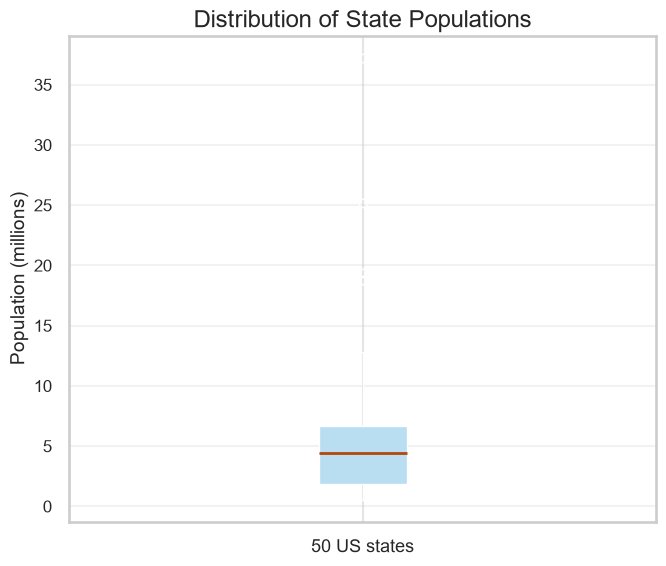

In [28]:
import matplotlib.pyplot as plt

population_millions = state["Population"] / 1_000_000

fig, ax = plt.subplots(figsize=(7, 6))

ax.boxplot(
    population_millions,
    whis=1.5,
    patch_artist=True,
    boxprops={"facecolor": "#B9DDF1"},
    medianprops={"color": "#B54708", "linewidth": 2},
)

ax.set_title("Distribution of State Populations", fontsize=17)
ax.set_ylabel("Population (millions)", fontsize=14)
ax.set_xticks([1])
ax.set_xticklabels(["50 US states"], fontsize=13)
ax.tick_params(axis="y", labelsize=12)
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

### Reading the Population Boxplot

- Median population: approximately **4.44 million**.
- Middle 50%: approximately **1.83–6.68 million**.
- Several large states appear beyond the upper whisker.

The high end extends much farther than the low end.

**A boxplot summarizes spread and asymmetry,
but can hide clusters and multiple peaks.**

## 4.3 · Frequency Tables

**Frequency table:** Counts observations within
a set of intervals called **bins**.

For equal-width bins:
- Interval widths are equal.
- Counts can differ.
- Empty bins remain visible.

**Question:** Where do state populations concentrate?

In [29]:
import numpy as np
import pandas as pd

population_millions = state["Population"] / 1_000_000

# Ten equal-width bins, shared by the table and histogram.
bin_edges = np.linspace(
    population_millions.min(),
    population_millions.max(),
    11,
)

counts, _ = np.histogram(population_millions, bins=bin_edges)

frequency_table = pd.DataFrame({
    "From (millions)": bin_edges[:-1],
    "To (millions)": bin_edges[1:],
    "Number of states": counts,
})

frequency_table.round(2)

,From (millions),To (millions),Number of states
0,0.56,4.23,24
1,4.23,7.90,14
2,7.90,11.57,6
3,11.57,15.24,2
4,15.24,18.91,1
5,18.91,22.58,1
6,22.58,26.25,1
7,26.25,29.92,0
8,29.92,33.58,0
9,33.58,37.25,1


### Interpretation · Population Frequencies

- **24 states** fall in the lowest bin.
- **14 states** fall in the next bin.
- **California** alone occupies the highest bin.
- Two bins immediately below California are empty.

**Empty intervals are information—not missing bars.**

Bin convention here: left edge included, right edge excluded,
except the final bin includes both edges.

## 4.4 · Histograms

**Histogram:** A visual display of frequencies
across numeric intervals.

- **Horizontal axis:** Values grouped into bins.
- **Vertical axis:** Number of observations per bin.
- Adjacent bins touch; empty bins create gaps.

**A histogram displays numeric intervals.
A bar chart compares categories.**

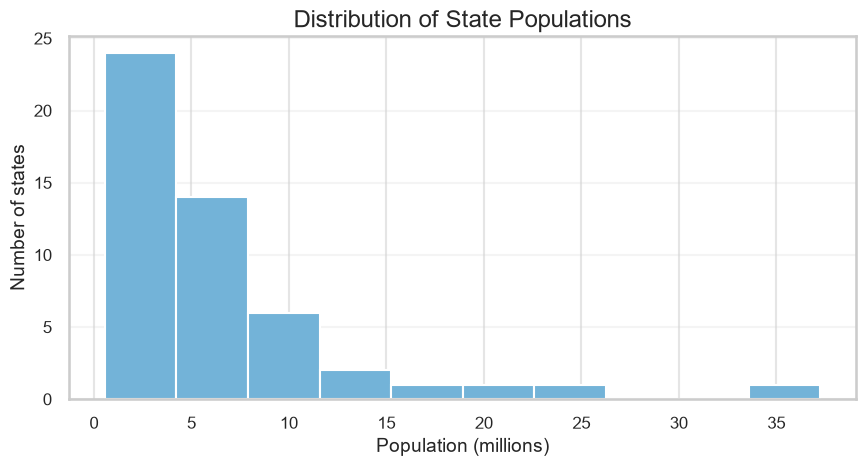

In [30]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    population_millions,
    bins=bin_edges,
    color="#73B3D8",
    edgecolor="white",
)

ax.set_title("Distribution of State Populations", fontsize=17)
ax.set_xlabel("Population (millions)", fontsize=14)
ax.set_ylabel("Number of states", fontsize=14)
ax.tick_params(labelsize=12)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### Reading the Shape

Most states have relatively small populations.
A few very large states extend the distribution to the right.

**Right-skewed:** The longer tail points toward larger values.

The tail direction—not where most observations sit—
determines the direction of skew.

### Bin Choice Changes the Picture

- **Too few bins:** Important features can disappear.
- **Too many bins:** The display can become noisy.

Inspect more than one reasonable bin width.

**Visible peaks and gaps may depend on bin boundaries.**

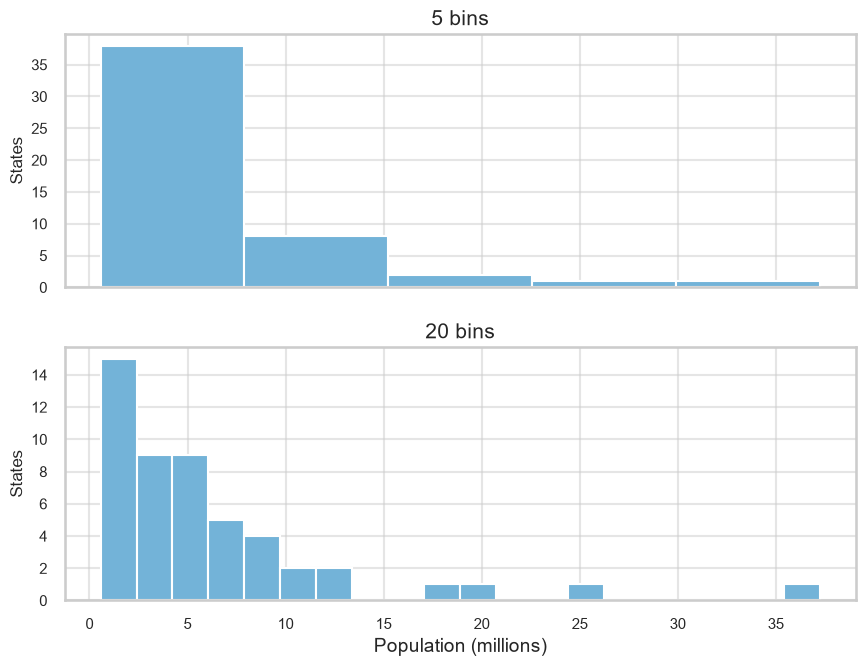

In [31]:
fig, axes = plt.subplots(
    2, 1, figsize=(9, 7), sharex=True
)

for ax, number_of_bins in zip(axes, [5, 20]):
    ax.hist(
        population_millions,
        bins=number_of_bins,
        color="#73B3D8",
        edgecolor="white",
    )
    ax.set_title(f"{number_of_bins} bins", fontsize=15)
    ax.set_ylabel("States", fontsize=12)
    ax.tick_params(labelsize=11)

axes[-1].set_xlabel("Population (millions)", fontsize=14)

plt.tight_layout()
plt.show()

### Equal Width versus Equal Count

| Approach | Interval width | Observations per interval |
|---|---|---|
| Equal-width frequency bins | Equal | Can differ |
| Quantile-based bins | Can differ | Approximately equal |

Ties can prevent quantile bins from having equal counts.

### Related Terms · Statistical Moments

- **Mean:** First raw moment; describes location.
- **Variance:** Second central moment; describes spread.
- **Skewness:** Standardized third central moment; describes asymmetry.
- **Kurtosis:** Standardized fourth central moment;
  sensitive to tail extremity.

**Numerical summaries complement visual inspection.**

## 4.5 · Density Plots

**Density plot:** A smooth estimate of a distribution,
usually calculated directly from the observations.

**Kernel density estimate (KDE):**
Combines small, smooth curves centered on the observations.

Think of it as a smoothed alternative to a histogram.

### Density Is Not a Count or a Probability

- The total area under a density curve is **1**.
- Area over an interval represents an estimated proportion.
- Curve height alone is not a probability.

For a density histogram:

$$
\text{Bar area} = \text{Height} \times \text{Bin width}
$$

**The bar areas—not necessarily their heights—sum to 1.**

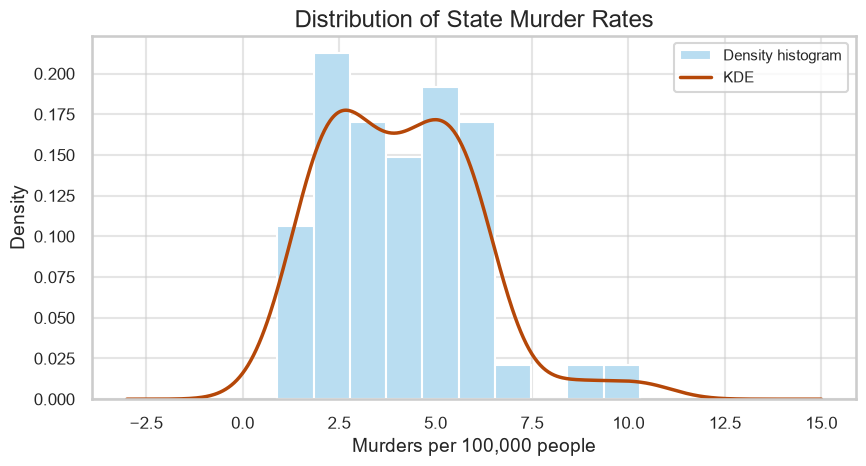

In [32]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

rates = state["Murder.Rate"].to_numpy()

kde = gaussian_kde(rates)
grid = np.linspace(-3, 15, 500)

fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    rates,
    bins=10,
    density=True,
    color="#B9DDF1",
    edgecolor="white",
    label="Density histogram",
)
ax.plot(
    grid, kde(grid),
    color="#B54708",
    linewidth=2.5,
    label="KDE",
)

ax.set_title("Distribution of State Murder Rates", fontsize=17)
ax.set_xlabel("Murders per 100,000 people", fontsize=14)
ax.set_ylabel("Density", fontsize=14)
ax.tick_params(labelsize=12)
ax.legend(fontsize=11)

plt.tight_layout()
plt.show()

### Reading the Plot

- Bars and curve describe the same observations.
- The curve smooths over individual values and bin boundaries.
- Peaks indicate regions of greater estimated concentration.

**A smooth curve is an estimate—not additional data.**

A Gaussian KDE can extend below zero,
even when negative values are impossible.

### Bandwidth · How Much Smoothing?

**Bandwidth:** Controls the width of the curves
used to construct the density estimate.

- **Small bandwidth:** More detail, but potentially noisy.
- **Large bandwidth:** Smoother, but may hide real features.

**The number and position of visible peaks
can depend on the bandwidth.**

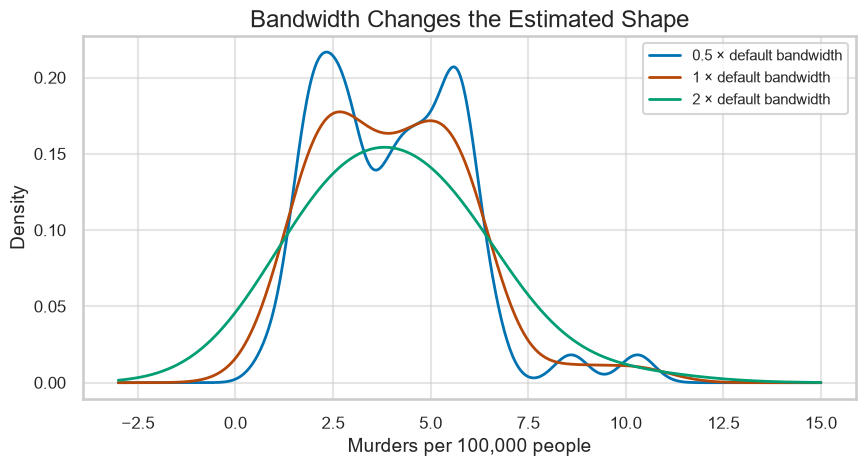

In [33]:
fig, ax = plt.subplots(figsize=(9, 5))

for factor, color in [
    (0.5, "#0072B2"),
    (1.0, "#B54708"),
    (2.0, "#009E73"),
]:
    estimate = gaussian_kde(rates)
    estimate.set_bandwidth(
        bw_method=estimate.factor * factor
    )
    ax.plot(
        grid, estimate(grid),
        linewidth=2,
        color=color,
        label=f"{factor:g} × default bandwidth",
    )

ax.set_title("Bandwidth Changes the Estimated Shape", fontsize=17)
ax.set_xlabel("Murders per 100,000 people", fontsize=14)
ax.set_ylabel("Density", fontsize=14)
ax.tick_params(labelsize=12)
ax.legend(fontsize=11)

plt.tight_layout()
plt.show()

### Part 4 · Choose the View

| Tool | Useful for |
|---|---|
| Percentiles | Position, center, and tails |
| Boxplot | Compact summary and group comparisons |
| Frequency table | Counts within numeric intervals |
| Histogram | Shape, concentrations, and gaps |
| Density plot | A smooth estimate of shape |

**Use complementary views.
Check how bins and smoothing affect the story.**

# Part 5 · Exploring Binary and Categorical Data

## 5.1 · Counts and Proportions

Summarize a categorical variable by counting
how often each category occurs.

$$
\text{Proportion} = \frac{\text{Category count}}{\text{Total count}}
$$

For a binary variable coded 0/1,
**the mean equals the proportion of 1s**.

In [34]:
import pandas as pd

# Synthetic purchase outcomes
purchased = pd.Series([0, 1, 0, 1, 1, 0, 0, 1])

print(f"Purchases: {purchased.sum()} of {len(purchased)}")
print(f"Purchase proportion: {purchased.mean():.0%}")

Purchases: 4 of 8
Purchase proportion: 50%


## 5.2 · Example: Flight Delays by Cause

The book summarizes delay causes at
Dallas/Fort Worth Airport.

- **Carrier:** Factors under airline control.
- **ATC:** Air traffic control system.
- **Weather**
- **Security**
- **Inbound:** Late arrival of the incoming aircraft.

**These percentages describe the distribution of delay causes,
not the percentage of all flights delayed.**

In [35]:
# Percentages reported in the book's Table 1-6
delay_percent = pd.Series({
    "Carrier": 23.02,
    "ATC": 30.40,
    "Weather": 4.03,
    "Security": 0.12,
    "Inbound": 42.43,
})

delay_percent.rename("Percentage of delays").to_frame()

,Percentage of delays
Carrier,23.02
ATC,30.40
Weather,4.03
Security,0.12
Inbound,42.43


## 5.3 · Bar Charts

**Bar chart:** Displays a count or proportion
for each category.

- Categories occupy separate positions.
- Bar height represents the count or proportion.
- Nominal categories have no inherent numerical spacing.

**Use a zero baseline so bar lengths represent values fairly.**

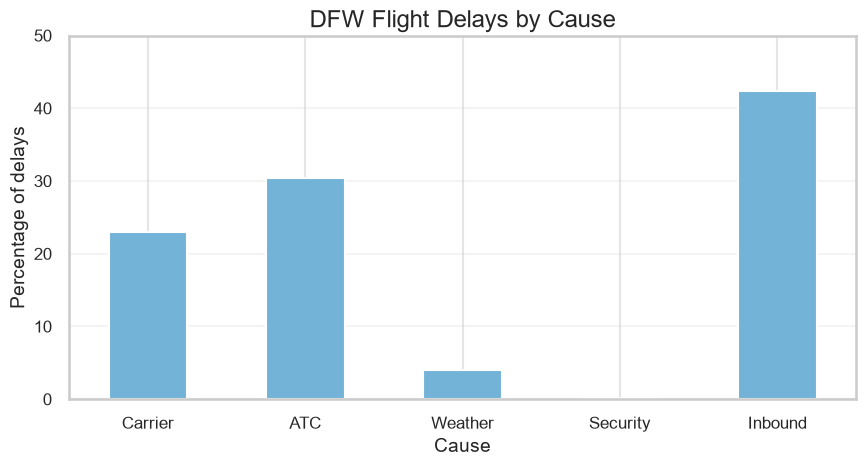

In [36]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5))

delay_percent.plot.bar(
    ax=ax,
    color="#73B3D8",
    edgecolor="white",
    rot=0,
)

ax.set_title("DFW Flight Delays by Cause", fontsize=17)
ax.set_xlabel("Cause", fontsize=14)
ax.set_ylabel("Percentage of delays", fontsize=14)
ax.set_ylim(0, 50)
ax.tick_params(labelsize=12)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### Bar Chart versus Histogram

| Bar chart | Histogram |
|---|---|
| Compares categories | Groups numeric values into intervals |
| Bars are usually separated | Adjacent intervals usually touch |
| Nominal categories can be reordered | Numeric intervals retain their order |

**Ordinal categories should retain their meaningful order.**

### What About Pie Charts?

**Pie chart:** Represents category proportions
as slices of a whole.

Useful only when the categories form a meaningful whole.

**Bar charts generally make close comparisons easier.**
Lengths are easier to compare than angles and areas.

## 5.4 · Mode

**Mode:** The most frequently occurring value or category.

- A tie can produce multiple modes.
- For the delay example, the mode is **Inbound**.

**Most common does not necessarily mean a majority.**
Inbound is the largest category, but accounts for less than 50%.

In [37]:
# These are already aggregated percentages:
# find the category with the largest share.
print("Most common delay cause:", delay_percent.idxmax())

Most common delay cause: Inbound


### Numeric Data Can Become Categories

**Binning:** Converting numeric values into intervals,
such as low, medium, and high.

This can simplify exploration and reveal relationships.

**Tradeoff:** Values within an interval lose their distinctions.
Results can depend on the chosen boundaries.

## 5.5 · Expected Value

**Expected value:** A probability-weighted average
of the possible numerical outcomes.

$$
E[X] = \sum_i p_i x_i
$$

- $x_i$: a possible outcome.
- $p_i$: its probability.
- Probabilities sum to **1**.

The outcomes must have a meaningful numerical scale.

### Example · Revenue per Webinar Attendee

A cloud-service company estimates:

| Outcome | Monthly revenue | Probability |
|---|---:|---:|
| Premium subscription | \$300 | 5% |
| Basic subscription | \$50 | 15% |
| No subscription | \$0 | 80% |

**Question:** What is the expected monthly revenue
per attendee?

In [38]:
import numpy as np
import pandas as pd

offers = pd.DataFrame({
    "Outcome": ["Premium", "Basic", "No subscription"],
    "Monthly revenue": [300, 50, 0],
    "Probability": [0.05, 0.15, 0.80],
})

offers["Contribution"] = (
        offers["Monthly revenue"] * offers["Probability"]
)

display(offers)

expected_revenue = offers["Contribution"].sum()
print(f"Expected monthly revenue per attendee: ${expected_revenue:.2f}")

,Outcome,Monthly revenue,Probability,Contribution
0,Premium,300,0.05,15.0
1,Basic,50,0.15,7.5
2,No subscription,0,0.80,0.0


Expected monthly revenue per attendee: $22.50


### Interpretation

$$
E[X] = 0.05(300) + 0.15(50) + 0.80(0) = \$22.50
$$

**$22.50 is an average—not an individual subscription price.**

An attendee contributes $0, $50, or $300.
The expected value summarizes these uncertain outcomes.

It represents revenue, not profit.

### Expected Total Revenue

For 100 attendees with these same probabilities:

$$
E[\text{Total revenue}] = 100 \times \$22.50 = \$2{,}250
$$

Actual revenue can differ.

**Expected totals add even when outcomes are dependent.**
Independence matters for assessing variability.

## 5.6 · Probability

**Probability:** A numerical measure of how likely
an event is, between 0 and 1.

A useful interpretation:
the long-run proportion of occurrences
under repeated, comparable conditions.

**Observed proportions can estimate probabilities.
They do not guarantee future frequencies.**

### Probability versus Odds

For an event with probability $p$:

$$
\text{Odds in favor} = \frac{p}{1-p}
$$

If the odds in favor are $a:b$:

$$
p = \frac{a}{a+b}
$$

**Example:** Odds of 2:1 in favor correspond
to probability $2/3$, approximately 66.7%.

### Part 5 · Key Takeaways

- Use counts and proportions to summarize categories.
- Use bar charts to compare category frequencies.
- The mode identifies the most common category.
- Expected value combines numerical outcomes
  with their probabilities.

**Always identify the denominator
and what the numerical values represent.**

# Part 6 · Correlation

## 6.1 · How Do Two Numeric Variables Move Together?

**Positive association:** Larger values of one variable
tend to accompany larger values of the other.

**Negative association:** Larger values of one variable
tend to accompany smaller values of the other.

Explore relationships between predictors,
and between predictors and an outcome.

## 6.2 · Pearson’s Correlation Coefficient

**Pearson’s r:** Measures the direction and strength
of a linear association between paired numeric variables.

$$
-1 \le r \le 1
$$

| Value | Meaning |
|---|---|
| +1 | Perfect positive linear relationship |
| −1 | Perfect negative linear relationship |
| Near 0 | Weak or absent linear relationship |

**Near-zero correlation does not rule out a nonlinear relationship.**

### From Shared Movement to a Standardized Measure

Multiply the paired deviations from their means:

- Same signs → positive product.
- Opposite signs → negative product.

Add these products, then standardize using both spreads.

**Standardization makes the result unitless and comparable.**

### Pearson’s r · Formula

$$
r =
\frac{\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y})}
{(n-1)s_xs_y}
$$

- $(x_i, y_i)$: paired observations.
- $\bar{x}, \bar{y}$: sample means.
- $s_x, s_y$: sample standard deviations.

Both variables must have nonzero variability.
Correlation with a constant variable is undefined.

## 6.3 · Scatterplots

**Scatterplot:** Displays paired numeric observations.

- Horizontal axis: one variable.
- Vertical axis: the other variable.
- Each point: one record.

**Inspect the pattern alongside the coefficient.**

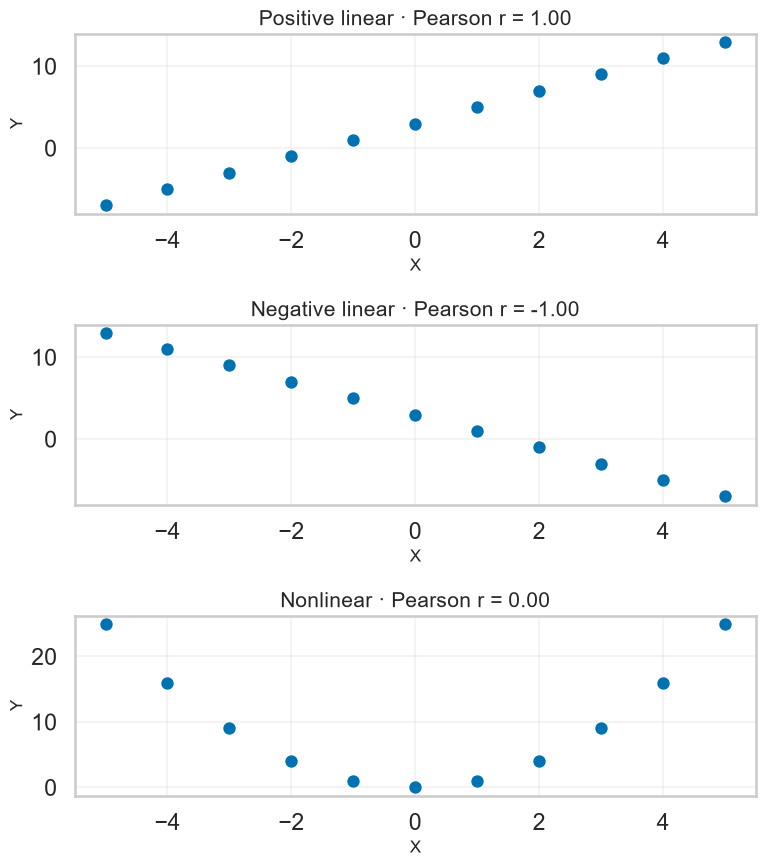

In [39]:
import numpy as np
import matplotlib.pyplot as plt

# Synthetic examples
x = np.arange(-5, 6)

examples = [
    ("Positive linear", 2 * x + 3),
    ("Negative linear", -2 * x + 3),
    ("Nonlinear", x ** 2),
]

fig, axes = plt.subplots(3, 1, figsize=(8, 9))

for ax, (label, y) in zip(axes, examples):
    r = np.corrcoef(x, y)[0, 1]

    ax.scatter(x, y, s=55, color="#0072B2")
    ax.set_title(f"{label} · Pearson r = {r:.2f}", fontsize=15)
    ax.set_xlabel("X", fontsize=12)
    ax.set_ylabel("Y", fontsize=12)
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

### Interpretation

- **Positive straight line:** r = +1.
- **Negative straight line:** r = −1.
- **Symmetric U-shaped pattern:** r = 0.

In the U-shaped example, Y is completely determined by X,
despite zero Pearson correlation.

**Correlation measures linear association—not every relationship.**

## 6.4 · Correlation Is Sensitive to Outliers

An extreme observation can strengthen, weaken,
or reverse Pearson’s correlation.

**Check the scatterplot before interpreting r.**

An unusual observation deserves investigation;
it is not automatically an error.

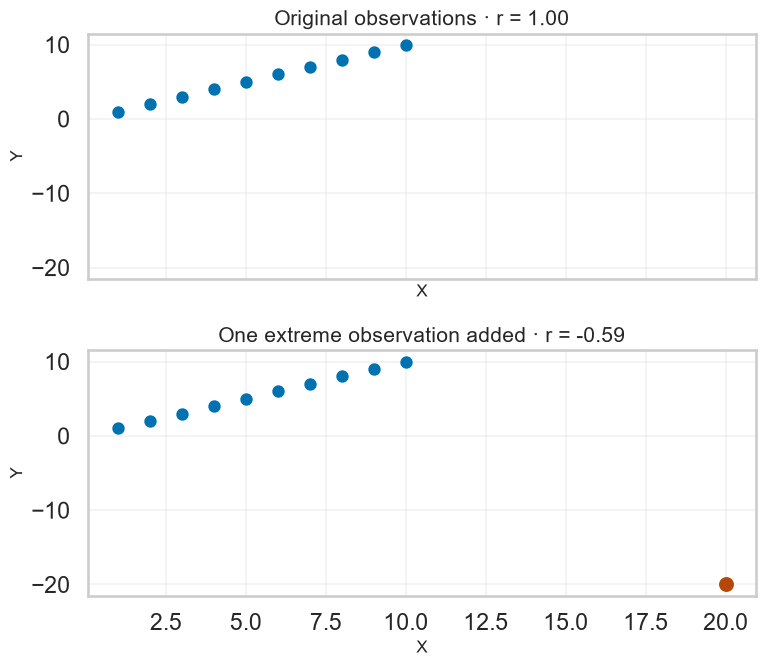

In [40]:
import numpy as np
import matplotlib.pyplot as plt

# Synthetic example: add one observation to a perfect line.
x = np.arange(1, 11)
y = x.copy()

x_extreme = np.append(x, 20)
y_extreme = np.append(y, -20)

fig, axes = plt.subplots(2, 1, figsize=(8, 7), sharex=True, sharey=True)

for ax, a, b, title in [
    (axes[0], x, y, "Original observations"),
    (axes[1], x_extreme, y_extreme, "One extreme observation added"),
]:
    r = np.corrcoef(a, b)[0, 1]
    ax.scatter(a, b, s=55, color="#0072B2")
    ax.set_title(f"{title} · r = {r:.2f}", fontsize=15)
    ax.set_xlabel("X", fontsize=12)
    ax.set_ylabel("Y", fontsize=12)
    ax.grid(alpha=0.2)

axes[1].scatter(20, -20, s=85, color="#B54708", zorder=3)

plt.tight_layout()
plt.show()

### Interpretation

The original observations follow a perfect positive line.

Adding one extreme pair reverses the sign of Pearson’s r.

**A single coefficient can conceal the structure
of most observations.**

## 6.5 · Rank-Based Correlations

**Spearman’s rho:** Pearson correlation calculated
on the ranks of the observations.

**Kendall’s tau:** Measures agreement between
the orderings of pairs of observations.

Both describe **monotonic association**:
as one variable increases, the other tends
to move consistently in one direction.

Ranks reduce sensitivity to extreme magnitudes,
but do not make these measures immune to unusual observations.

### Example · Increasing, but Not Linear

$$
Y = X^3
$$

The relationship curves, but larger X always gives larger Y.

**Spearman correlation can be perfect
even when Pearson correlation is not.**

In [41]:
import pandas as pd

curved = pd.DataFrame({
    "X": np.arange(1, 11),
})
curved["Y"] = curved["X"] ** 3

pd.Series({
    "Pearson": curved["X"].corr(curved["Y"], method="pearson"),
    "Spearman": curved["X"].corr(curved["Y"], method="spearman"),
    "Kendall": curved["X"].corr(curved["Y"], method="kendall"),
}, name="Correlation").round(3).to_frame()

,Correlation
Pearson,0.928
Spearman,1.000
Kendall,1.000


### Interpretation and Cautions

- Spearman and Kendall equal **1** here:
  the orderings agree perfectly.
- Pearson is below **1**:
  the relationship is not a straight line.

Rank-based methods do not detect every nonlinear pattern.

**Correlation does not establish causation.**
Shared causes, selection, or chance can produce associations.

## 6.6 · Correlation Matrices

**Correlation matrix:** A table of pairwise correlations,
with the same variables on its rows and columns.

- Diagonal entries are **1** for nonconstant variables.
- The matrix is symmetric: corr(X, Y) = corr(Y, X).
- Each off-diagonal cell describes one pair.

### Example · Telecommunications Stocks

The book compares historical daily stock movements
from July 2012 through June 2015.

| Symbol | Company |
|---|---|
| T | AT&T |
| CTL | CenturyLink |
| FTR | Frontier |
| VZ | Verizon |
| LVLT | Level 3 |

**Compare paired daily movements—not stock-price levels.**

In [42]:
import pandas as pd

base_url = (
    "https://raw.githubusercontent.com/gedeck/"
    "practical-statistics-for-data-scientists/master/data/"
)

# Load once: the compressed file is approximately 20 MB.
stock_movements = pd.read_csv(
    base_url + "sp500_data.csv.gz",
    index_col=0,
    parse_dates=True,
)

# The supplied data already contain daily movements.
telecom = stock_movements.loc[
    (stock_movements.index > "2012-07-01")
    & (stock_movements.index <= "2015-06-30"),
    ["T", "CTL", "FTR", "VZ", "LVLT"],
]

telecom.corr().round(3)

,T,CTL,FTR,VZ,LVLT
T,1.000,0.475,0.328,0.678,0.279
CTL,0.475,1.000,0.420,0.417,0.287
FTR,0.328,0.420,1.000,0.288,0.260
VZ,0.678,0.417,0.288,1.000,0.242
LVLT,0.279,0.287,0.260,0.242,1.000


### Interpretation · The Book’s Results

- **AT&T and Verizon:** r ≈ 0.678.
- All five stocks have positive pairwise correlations.
- Level 3 has relatively weak correlations with the others.

**Positive correlation means a tendency to move together,
not agreement on every day.**

These are historical relationships, not fixed properties.

## 6.7 · Correlation Heatmaps

**Heatmap:** Uses color to display the correlation matrix.

Use a consistent scale from **−1 to +1**,
with a neutral color at **0**.

Color shows the pattern; numbers give precise values.

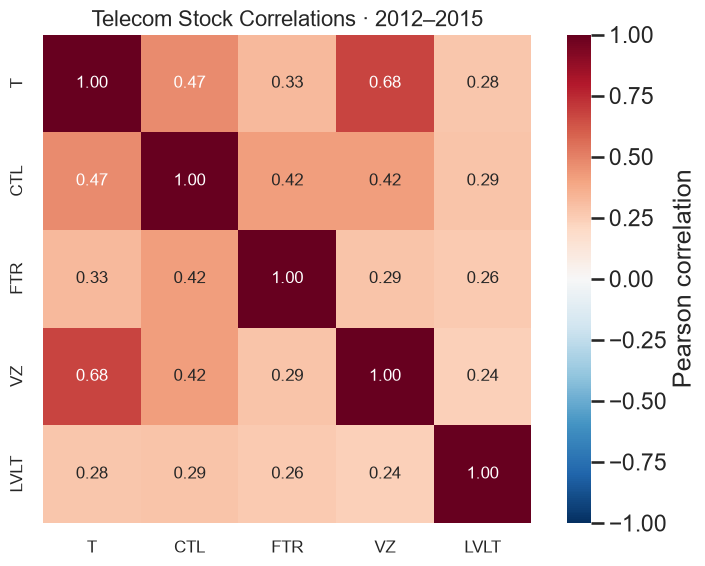

In [43]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    telecom.corr(),
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    annot_kws={"fontsize": 12},
    cbar_kws={"label": "Pearson correlation"},
    ax=ax,
)

ax.set_title("Telecom Stock Correlations · 2012–2015", fontsize=16)
ax.tick_params(labelsize=12)

plt.tight_layout()
plt.show()

### Inspect a Pair · AT&T and Verizon

Each point represents the paired movements on one trading day.

- Upper-right: both increased.
- Lower-left: both decreased.
- Other quadrants: moved in opposite directions.

**Look for direction, unusual observations,
and concentrations hidden by overlapping points.**

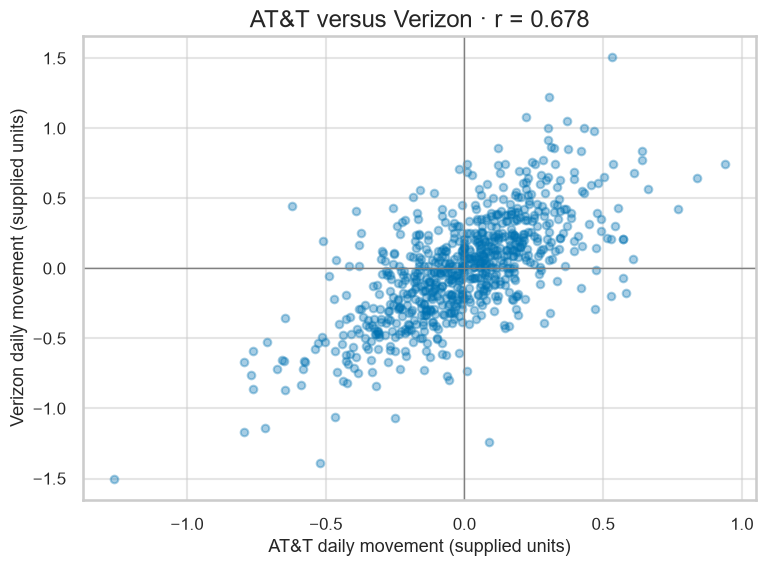

In [44]:
paired = telecom[["T", "VZ"]].dropna()
r = paired["T"].corr(paired["VZ"])

fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(
    paired["T"],
    paired["VZ"],
    alpha=0.35,
    s=30,
    color="#0072B2",
)

ax.axhline(0, color="gray", linewidth=1)
ax.axvline(0, color="gray", linewidth=1)
ax.set_title(f"AT&T versus Verizon · r = {r:.3f}", fontsize=17)
ax.set_xlabel("AT&T daily movement (supplied units)", fontsize=13)
ax.set_ylabel("Verizon daily movement (supplied units)", fontsize=13)
ax.tick_params(labelsize=12)

plt.tight_layout()
plt.show()

## 6.8 · Example: Correlations Across ETFs

**Exchange-traded fund (ETF):**
A fund traded on an exchange, often tracking
an index, sector, or investment strategy.

The book compares historical daily movements
across several ETFs.

**Question:** Which move together,
and which behave differently?

In [45]:
# Reuse base_url and stock_movements from the previous example.
symbols = pd.read_csv(base_url + "sp500_sectors.csv")

etf_symbols = symbols.loc[
    symbols["sector"] == "etf", "symbol"
].tolist()

etfs = stock_movements.loc[
    (stock_movements.index > "2012-07-01")
    & (stock_movements.index <= "2015-06-30"),
    etf_symbols,
]

etf_correlations = etfs.corr()

### Read the Symbols

| Symbol | Exposure in this historical example |
|---|---|
| SPY | S&P 500 |
| DIA | Dow Jones Industrial Average |
| QQQ | Nasdaq-100 |
| XLK | Technology sector |
| GLD | Gold |
| USO | Oil futures |
| VXX | Short-term volatility futures |

These represent different exposures,
not equivalent types of investments.

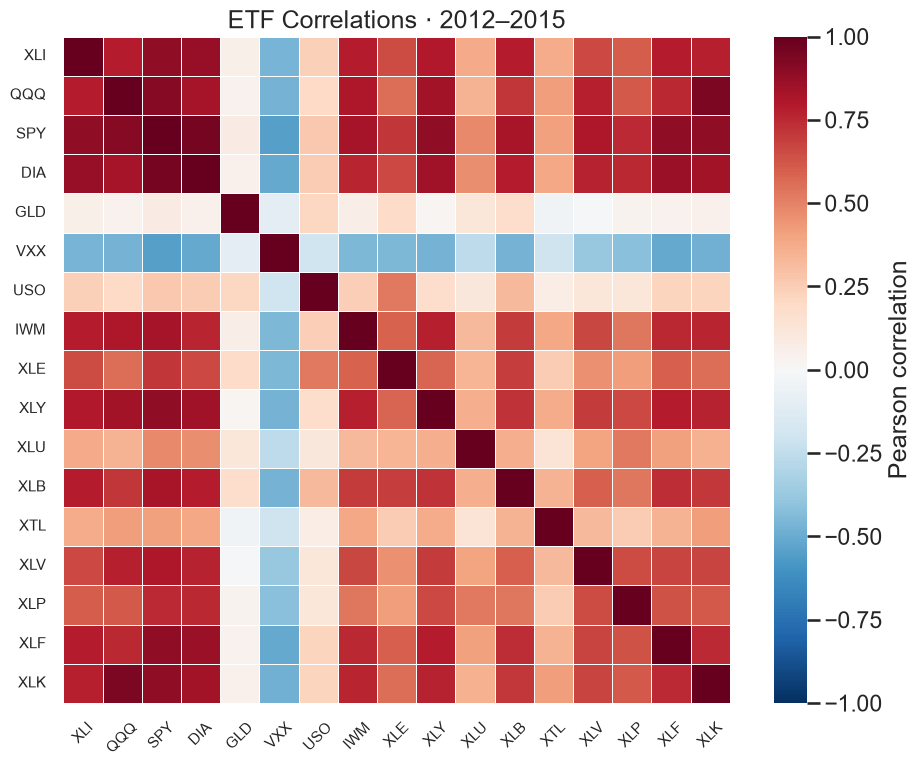

In [46]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 8))

sns.heatmap(
    etf_correlations,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.4,
    cbar_kws={"label": "Pearson correlation"},
    ax=ax,
)

ax.set_title("ETF Correlations · 2012–2015", fontsize=18)
ax.tick_params(axis="x", labelrotation=45, labelsize=11)
ax.tick_params(axis="y", labelrotation=0, labelsize=11)

plt.tight_layout()
plt.show()

### Interpretation · Historical Patterns

- **SPY and DIA:** Strong positive association.
- **QQQ and XLK:** Positive association,
  consistent with overlapping technology exposure.
- Gold, oil, and volatility exposures show different patterns;
  some relationships are weak or negative.

**Read each pair separately.
Relationships can change across time periods.**

### Part 6 · Key Takeaways

- Pearson’s r measures **linear** association.
- Its sign indicates direction; magnitude indicates strength.
- Outliers can strongly affect the result.
- Rank-based measures describe monotonic association.
- Matrices and heatmaps summarize many pairs.
- Scatterplots reveal structure a coefficient can hide.

**Zero correlation does not imply independence.
Correlation does not establish causation.**

### Before Interpreting a Correlation

Check:

- Are observations paired correctly?
- Is either variable constant?
- Are missing values changing which rows enter each pair?
- Is the relationship nonlinear or driven by unusual points?
- Does the chosen time period affect the result?

**Pairwise patterns do not describe every relationship
among three or more variables.**

# Part 7 · Exploring Two or More Variables

## 7.1 · Match the Method to the Variables

| Variables | Useful displays |
|---|---|
| Numeric + numeric | Scatterplot, hexbin, density contours |
| Categorical + categorical | Contingency table |
| Categorical + numeric | Grouped boxplots, violin plots |
| Three or more variables | Grouping, color, faceting |

**Univariate:** One variable.
**Bivariate:** Two variables.
**Multivariate:** Multiple variables.

## 7.2 · When Scatterplots Become Too Dense

**Overplotting:** Observations overlap,
hiding their concentration and local patterns.

Possible responses:
- Smaller, transparent points.
- Binning observations into regions.
- Estimating two-dimensional density.

**A dark cloud can hide meaningful structure.**

### Example · King County Housing

The book compares:

- **Finished living area:** Square feet.
- **Tax-assessed value:** Dollars.

For the demonstration, retain:
- Living area above 100 and below 3,500 square feet.
- Assessed value below $750,000.

**These filters change the population shown.
The plot does not describe all properties.**

In [47]:
import pandas as pd

base_url = (
    "https://raw.githubusercontent.com/gedeck/"
    "practical-statistics-for-data-scientists/master/data/"
)

housing = pd.read_csv(base_url + "kc_tax.csv.gz")

housing_view = housing.loc[
    (housing["SqFtTotLiving"] > 100)
    & (housing["SqFtTotLiving"] < 3500)
    & (housing["TaxAssessedValue"] < 750_000),
    ["SqFtTotLiving", "TaxAssessedValue", "ZipCode"],
].dropna(subset=["SqFtTotLiving", "TaxAssessedValue"])

print(f"Properties shown: {len(housing_view):,}")
housing_view.head()

Properties shown: 432,693


,SqFtTotLiving,TaxAssessedValue,ZipCode
1,1870,206000.0,98002.0
2,1530,303000.0,98166.0
3,2000,361000.0,98108.0
4,3150,459000.0,98108.0
5,1570,223000.0,98032.0


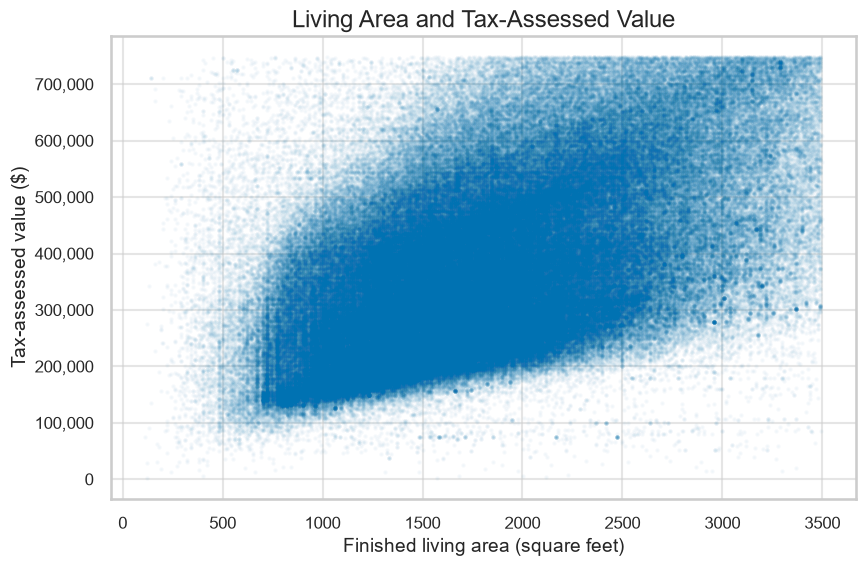

In [48]:
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    housing_view["SqFtTotLiving"],
    housing_view["TaxAssessedValue"],
    s=3,
    alpha=0.03,
    color="#0072B2",
    rasterized=True,
)

ax.set_title("Living Area and Tax-Assessed Value", fontsize=17)
ax.set_xlabel("Finished living area (square feet)", fontsize=14)
ax.set_ylabel("Tax-assessed value ($)", fontsize=14)
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.tick_params(labelsize=12)

plt.tight_layout()
plt.show()

## 7.3 · Hexagonal Binning

**Hexagonal binning:** Divides the plotting area
into hexagons and counts observations in each one.

- Position represents the two numeric variables.
- Color represents the number of observations.

**The two-dimensional counterpart of a frequency histogram.**

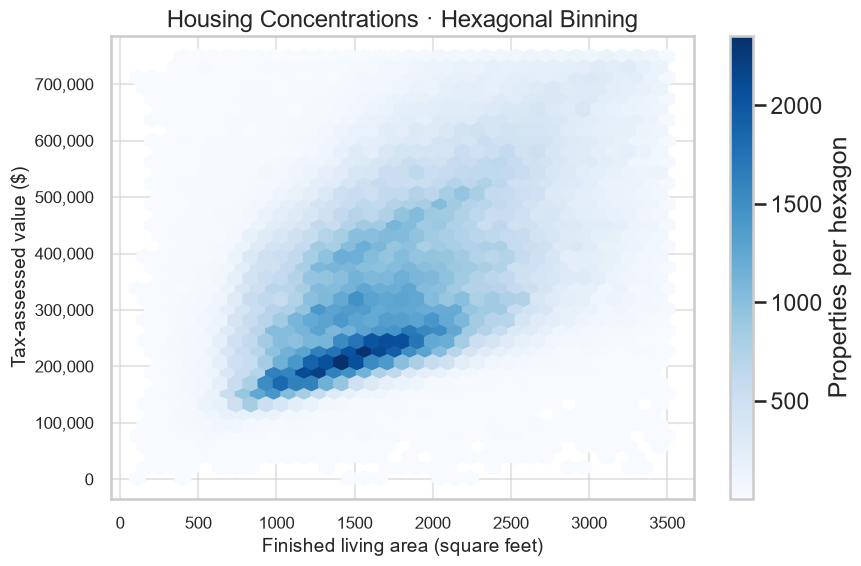

In [49]:
fig, ax = plt.subplots(figsize=(9, 6))

hexagons = ax.hexbin(
    housing_view["SqFtTotLiving"],
    housing_view["TaxAssessedValue"],
    gridsize=35,
    mincnt=1,
    cmap="Blues",
)

fig.colorbar(hexagons, ax=ax, label="Properties per hexagon")

ax.set_title("Housing Concentrations · Hexagonal Binning", fontsize=17)
ax.set_xlabel("Finished living area (square feet)", fontsize=14)
ax.set_ylabel("Tax-assessed value ($)", fontsize=14)
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.tick_params(labelsize=12)

plt.tight_layout()
plt.show()

### Interpretation

- Larger living areas tend to accompany higher assessed values.
- Darker hexagons identify concentrations of properties.
- Additional bands suggest that similarly sized properties
  can have different assessed values.

**Living area alone does not explain all the variation.**

Tax-assessed value is not the same as sale price.

### Binning Choices Still Matter

**Grid size:** Controls the resolution of the hexagons.

- Coarse grid: clearer overview, less detail.
- Fine grid: more detail, potentially sparse counts.

**Color represents counts here—not assessed value.
Read the colorbar before interpreting the plot.**

## 7.4 · Density Contours

**Density contour:** A line connecting locations
with the same estimated two-dimensional density.

Like a topographic map:
- Terrain height becomes concentration of observations.
- Nested contours outline regions of higher concentration.

**A two-dimensional extension of a density curve.**

### Example · Housing Density

Estimate the joint distribution of:
- Finished living area.
- Tax-assessed value.

For faster demonstration, use a reproducible
random sample of up to **5,000 properties**.

**The contours describe an estimate from this sample,
not exact counts from the full dataset.**

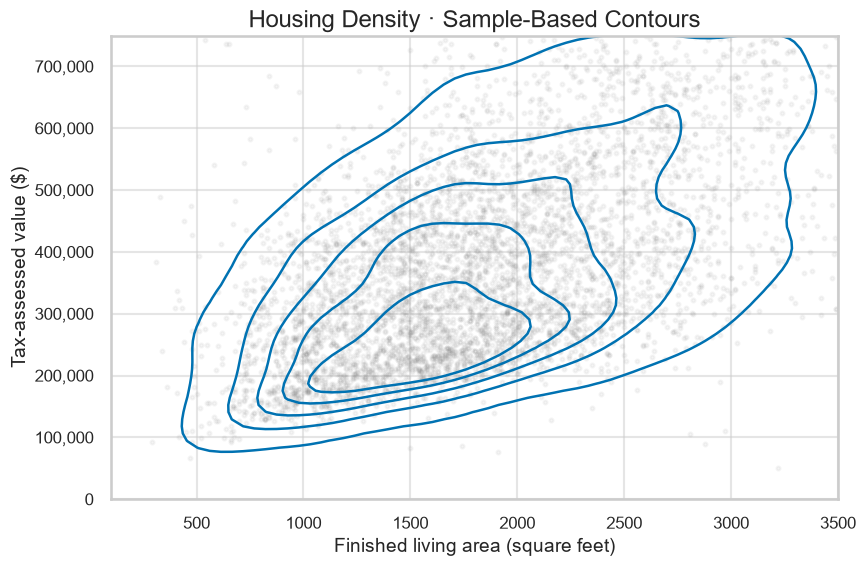

In [50]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

housing_sample = housing_view.sample(
    n=min(5000, len(housing_view)),
    random_state=42,
)

fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    housing_sample["SqFtTotLiving"],
    housing_sample["TaxAssessedValue"],
    s=8,
    alpha=0.08,
    color="gray",
)

sns.kdeplot(
    data=housing_sample,
    x="SqFtTotLiving",
    y="TaxAssessedValue",
    levels=6,
    bw_adjust=1,
    gridsize=80,
    color="#0072B2",
    linewidths=1.8,
    ax=ax,
)

ax.set_title("Housing Density · Sample-Based Contours", fontsize=17)
ax.set_xlabel("Finished living area (square feet)", fontsize=14)
ax.set_ylabel("Tax-assessed value ($)", fontsize=14)
ax.set_xlim(100, 3500)
ax.set_ylim(0, 750_000)
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.tick_params(labelsize=12)

plt.tight_layout()
plt.show()

### Reading the Contours

Look for:
- The main concentration of properties.
- The direction in which the concentration extends.
- Additional concentrations or bands.

**Bandwidth and sampling can change visible details.**

Contours extending toward similar living areas
but different values suggest other variables may matter.

### Three Views of Two Numeric Variables

| Display | What it shows |
|---|---|
| Scatterplot | Individual observations |
| Hexbin | Counts within two-dimensional bins |
| Density contours | Smoothed concentration patterns |

Heatmaps can also show two-dimensional counts or density.

**These displays reveal association;
they do not establish its cause.**

## 7.5 · Two Categorical Variables

**Contingency table:** Counts observations
for each combination of categories.

Also called a **cross-tabulation**.

- Rows: Categories of one variable.
- Columns: Categories of another.
- Cells: Counts for each combination.

**Percentages help compare groups of different sizes.**

### Example · Loan Grade and Status

The book uses Lending Club loan data.

**Grade:** A (highest) through G (lowest).

**Status:**
- Fully paid.
- Current.
- Late.
- Charged off: The remaining balance is considered uncollectible.

**Question:** How does the distribution of loan status
differ across grades?

In [51]:
import pandas as pd

base_url = (
    "https://raw.githubusercontent.com/gedeck/"
    "practical-statistics-for-data-scientists/master/data/"
)

loans = pd.read_csv(base_url + "lc_loans.csv")

counts = pd.crosstab(
    loans["grade"],
    loans["status"],
).reindex(list("ABCDEFG"))

counts

status,Charged Off,Current,Fully Paid,Late
grade,,,,
A,1562,50051,20408,469
B,5302,93852,31160,2056
C,6023,88928,23147,2777
D,5007,53281,13681,2308
E,2842,24639,5949,1374
F,1526,8444,2328,606
G,409,1990,643,199


### Counts versus Proportions

More charged-off loans in a grade can reflect:
- A larger number of loans.
- A higher charged-off proportion.
- Both.

To compare status distributions, calculate percentages
**within each grade**.

$$
\text{Row percentage}
=
\frac{\text{Cell count}}{\text{Total loans in that grade}}
\times 100
$$

In [52]:
row_percentages = counts.div(
    counts.sum(axis=1),
    axis=0,
) * 100

row_percentages.round(1)

status,Charged Off,Current,Fully Paid,Late
grade,,,,
A,2.2,69.0,28.2,0.6
B,4.0,70.9,23.5,1.6
C,5.0,73.6,19.1,2.3
D,6.7,71.7,18.4,3.1
E,8.2,70.8,17.1,3.9
F,11.8,65.4,18.0,4.7
G,12.6,61.4,19.8,6.1


### Interpretation · The Book’s Table

Charged-off loans represent approximately:

- **Grade A:** 2.2%
- **Grade G:** 12.6%

Lower grades have larger charged-off and late proportions
in this dataset.

**These are observed statuses—not final lifetime outcomes.**
Many loans are still current.

### Choose the Denominator

| Percentage | Question answered |
|---|---|
| Within a row | Among loans of this grade, what share has each status? |
| Within a column | Among loans with this status, what share has each grade? |
| Across the entire table | What share of all loans belongs to this combination? |

**Changing the denominator changes the question.**

In [53]:
# Optional comparison: inspect one table at a time.
column_percentages = counts.div(
    counts.sum(axis=0),
    axis=1,
) * 100

column_percentages.round(1)

status,Charged Off,Current,Fully Paid,Late
grade,,,,
A,6.9,15.6,21.0,4.8
B,23.4,29.2,32.0,21.0
C,26.6,27.7,23.8,28.4
D,22.1,16.6,14.1,23.6
E,12.5,7.7,6.1,14.0
F,6.7,2.6,2.4,6.2
G,1.8,0.6,0.7,2.0


### Key Takeaways

- Counts describe the size of each combination.
- Row percentages compare outcomes within groups.
- Column percentages describe the composition of an outcome.
- Always label the denominator.

**An association between grade and status
does not by itself establish causation.**

## 7.6 · Categorical and Numeric Data

Compare the distribution of a numeric variable
across categories.

**Example:** Carrier-delay percentages grouped by airline.

Look beyond the group averages:
- Typical level.
- Spread.
- Asymmetry.
- Unusual observations.

In [54]:
import pandas as pd

airline_stats = pd.read_csv(base_url + "airline_stats.csv")

airline_order = (
    airline_stats.groupby("airline")["pct_carrier_delay"]
    .median()
    .sort_values()
    .index
    .tolist()
)

airline_stats[["airline", "pct_carrier_delay"]].head()

,airline,pct_carrier_delay
0,American,8.153226
1,American,5.959924
2,American,7.157270
3,American,12.100000
4,American,7.333333


### Grouped Boxplots

**Grouped boxplots:** Display one boxplot per category,
using a shared numeric scale.

Compare:
- Median lines.
- Interquartile ranges.
- Whiskers and points beyond them.

**Shared axes make differences easier to assess.**

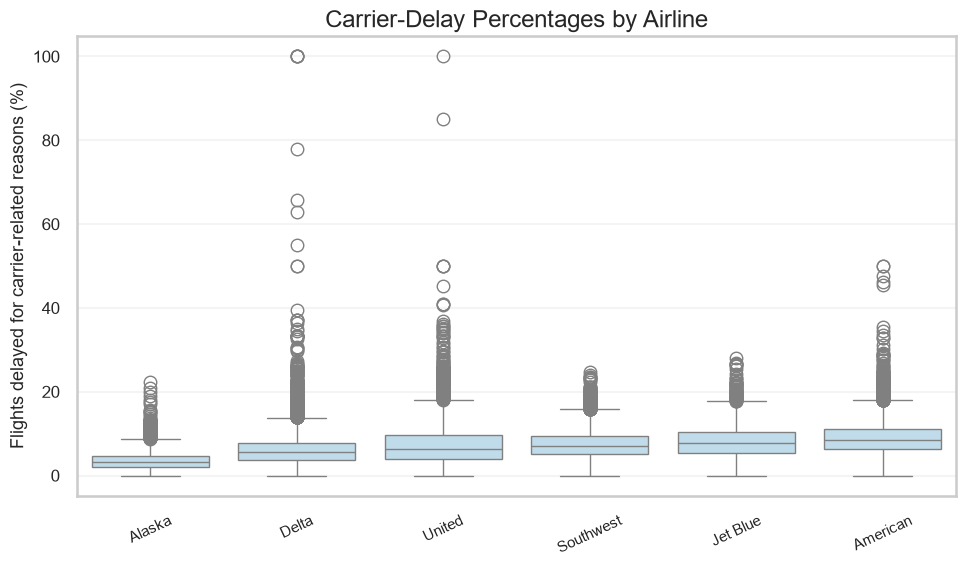

In [55]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 6))

sns.boxplot(
    data=airline_stats,
    x="airline",
    y="pct_carrier_delay",
    order=airline_order,
    color="#B9DDF1",
    whis=1.5,
    ax=ax,
)

ax.set_title("Carrier-Delay Percentages by Airline", fontsize=17)
ax.set_xlabel("")
ax.set_ylabel("Flights delayed for carrier-related reasons (%)", fontsize=13)
ax.tick_params(axis="x", labelrotation=25, labelsize=11)
ax.tick_params(axis="y", labelsize=12)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### Interpretation · The Book’s Comparison

- Alaska has relatively low carrier-delay percentages.
- American has relatively high percentages.
- American’s first quartile exceeds Alaska’s third quartile.

**The central halves of their distributions are separated.**

This describes the dataset.
It does not isolate the causal effect of the airline.

## 7.7 · Violin Plots

**Violin plot:** A mirrored density estimate
for each group.

- Position along the numeric axis: Observed values.
- Width: Estimated concentration.
- Inner marks can show quartiles.

**Reveals distribution shapes that a boxplot can hide.**

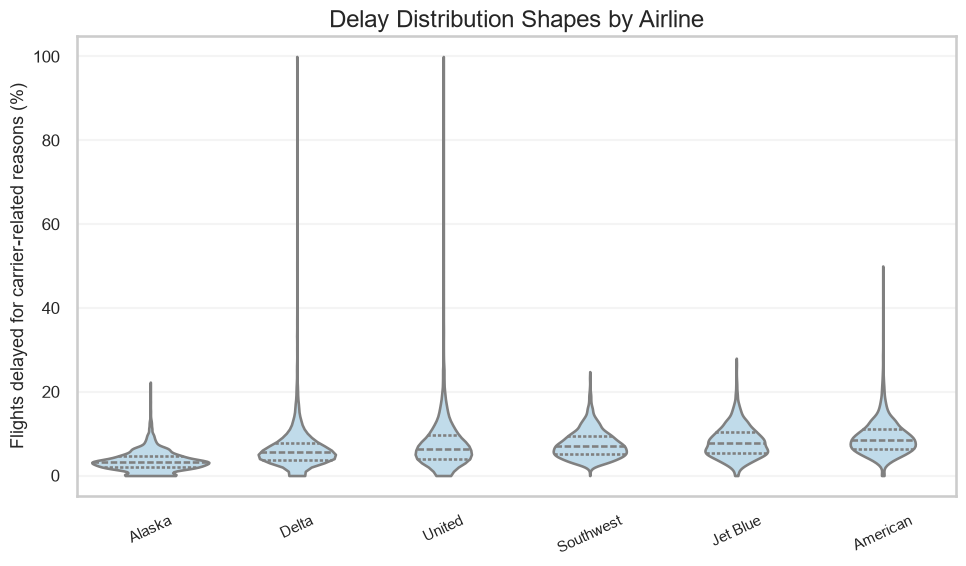

In [56]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.violinplot(
    data=airline_stats,
    x="airline",
    y="pct_carrier_delay",
    order=airline_order,
    inner="quartile",
    cut=0,
    color="#B9DDF1",
    ax=ax,
)

ax.set_title("Delay Distribution Shapes by Airline", fontsize=17)
ax.set_xlabel("")
ax.set_ylabel("Flights delayed for carrier-related reasons (%)", fontsize=13)
ax.tick_params(axis="x", labelrotation=25, labelsize=11)
ax.tick_params(axis="y", labelsize=12)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### Reading the Violins

Wider sections indicate greater estimated concentration.

The book highlights concentration near zero for Alaska,
and to a lesser extent Delta.

**Cautions:**
- Shape depends on smoothing and sample size.
- Width does not automatically represent group size.
- `cut=0` limits the drawn curve to the observed range.

### Boxplot or Violin Plot?

| Boxplot | Violin plot |
|---|---|
| Compact quartile summary | Shows estimated distribution shape |
| Clearly marks observations beyond whiskers | Can reveal concentrations and multiple peaks |
| Less dependent on smoothing choices | Depends on density estimation |

**Use the display that answers the comparison question.**

## 7.8 · Visualizing Multiple Variables

The housing plot showed different assessed values
for properties with similar living areas.

**Question:** Could location help explain those bands?

Add a third variable: **ZIP code**.

### Faceting and Conditioning

**Faceting:** Splitting a visualization into panels,
one for each category of another variable.

**Conditioning variable:** The variable defining those groups.

Here:
- X: Finished living area.
- Y: Tax-assessed value.
- Panels: ZIP codes.

**Compare relationships within groups,
not only across the combined dataset.**

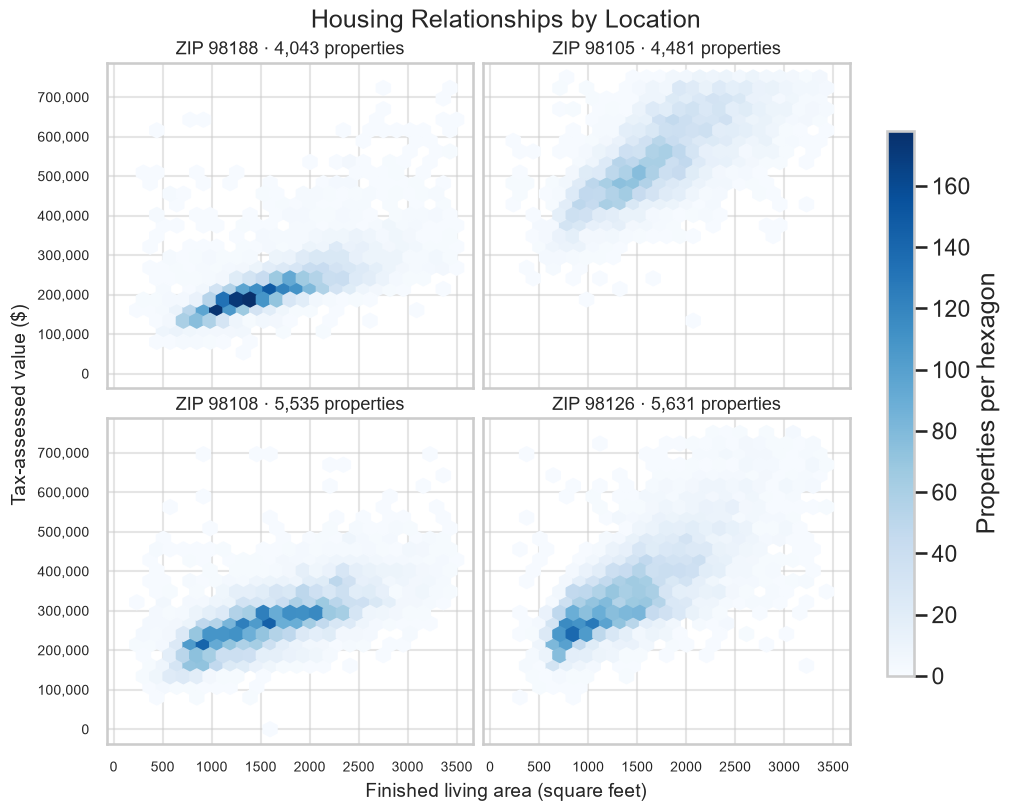

In [57]:
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

zip_codes = [98188, 98105, 98108, 98126]

fig, axes = plt.subplots(
    2, 2,
    figsize=(10, 8),
    sharex=True,
    sharey=True,
    layout="constrained",
)

plots = []

for ax, zip_code in zip(axes.flat, zip_codes):
    group = housing_view.loc[housing_view["ZipCode"] == zip_code]

    plot = ax.hexbin(
        group["SqFtTotLiving"],
        group["TaxAssessedValue"],
        gridsize=25,
        extent=(100, 3500, 0, 750_000),
        mincnt=1,
        cmap="Blues",
    )
    plots.append(plot)

    ax.set_title(f"ZIP {zip_code} · {len(group):,} properties", fontsize=13)
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    ax.tick_params(labelsize=10)

# Use the same color scale across all panels.
maximum_count = max(plot.get_array().max() for plot in plots)
for plot in plots:
    plot.set_clim(0, maximum_count)

fig.colorbar(
    plots[0],
    ax=axes.ravel().tolist(),
    label="Properties per hexagon",
    shrink=0.8,
)

fig.supxlabel("Finished living area (square feet)", fontsize=14)
fig.supylabel("Tax-assessed value ($)", fontsize=14)
fig.suptitle("Housing Relationships by Location", fontsize=18)

plt.show()

### Interpretation · Location Adds Context

In the book’s example, assessed values tend to be higher
in ZIP codes **98105 and 98126**
than in **98108 and 98188**, at comparable living areas.

Grouping by location helps clarify bands
seen in the combined plot.

**This is a descriptive association,
not proof that ZIP code itself causes the difference.**

### Compare Panels Fairly

- Keep numeric axes consistent.
- Use the same bin boundaries and color scale.
- Check how many observations each group contains.
- Distinguish counts from proportions or density.

**Darker panels may contain more observations,
rather than a greater relative concentration.**

### Part 7 · Key Takeaways

| Comparison | Useful tool |
|---|---|
| Numeric + numeric | Scatterplot, hexbin, contours |
| Categorical + categorical | Contingency table |
| Categorical + numeric | Grouped boxplots, violins |
| Relationships across groups | Faceting |

**The choice of display follows the variables
and the question.**

# Chapter 1 · Final Takeaways

1. Understand the observations and variable types.
2. Summarize both location and variability.
3. Inspect the full distribution.
4. Explore relationships with appropriate tables and plots.
5. Investigate unusual values and differences across groups.

**EDA builds understanding, reveals questions,
and guides the next steps of analysis.**